In [1]:
!echo $PYTHONPATH
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import date, datetime, timedelta, timezone
import subprocess, os, re
import numpy as np

CDT = timezone(timedelta(hours=-5))

def fmt_samweb_dt(dt):
    """Format a datetime as an ISO 8601 string with explicit CDT offset for SAM queries."""
    dt = dt.astimezone(CDT)
    tz = dt.strftime('%z')  # '-0500'
    return dt.strftime('%Y-%m-%dT%H:%M:%S') + f'{tz[:3]}:{tz[3:]}'


In [2]:
# set up sam_web_client

cmd = "source /cvmfs/fermilab.opensciencegrid.org/products/common/etc/setups.sh && setup sam_web_client && env"
result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
for line in result.stdout.splitlines():
    if '=' in line:
        key, _, val = line.partition('=')
        os.environ[key] = val


In [3]:
def numfiles_from_dataset(dataset, start_time, window_hours=1):
    """Query SAM for the number of files created in the specified dataset during the given time window."""
    start_date_str = fmt_samweb_dt(start_time)
    end_date_str   = fmt_samweb_dt(start_time + timedelta(hours=window_hours))
    command = f'samweb -e sbnd count-files \'defname:{dataset} and create_date >= "{start_date_str}" and create_date < "{end_date_str}"\''
    try:
        return int(subprocess.check_output(command, shell=True, executable='/bin/bash', stderr=subprocess.DEVNULL, text=True))
    except subprocess.CalledProcessError as e:
        print(f'Error for {dataset}: {e.output}')
        return None


Discovering chunk snapshot definitions (may take ~30s)...
Found 8 chunks: 00:00–07:00 CDT
  00:00 CDT: 11 files
  01:00 CDT: 0 files
  02:00 CDT: 10 files
  03:00 CDT: 1 files
  04:00 CDT: 9 files
  05:00 CDT: 4 files
  06:00 CDT: 8 files
  07:00 CDT: 4 files


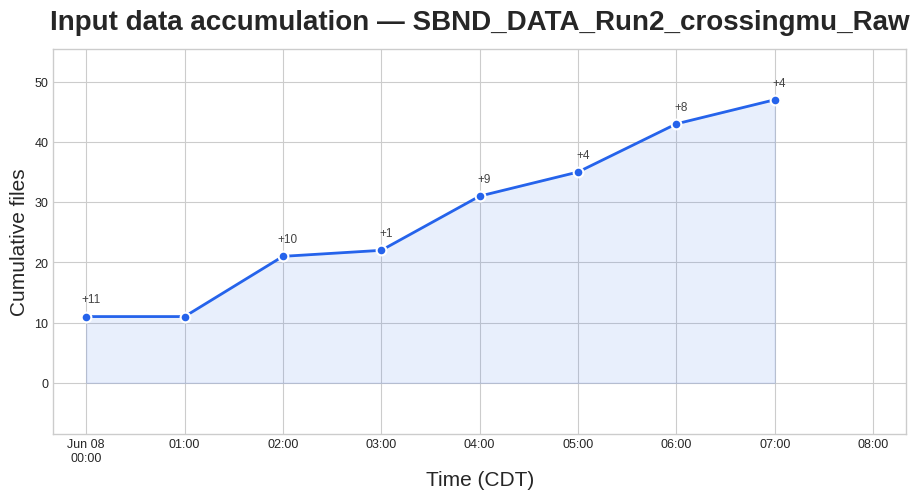

In [4]:
input_dataset = r"SBND_DATA_Run2_crossingmu_Raw"

# ── Discover POMS chunk snapshot definitions ─────────────────────────────────
# POMS names each 1-hour chunk: {dataset}_{uuid}_time_{start_unix}__{end_unix}
# Raw data files are catalogued in SAM well before processing, so their
# create_date does NOT align with the CDT job windows — use defname instead.
print("Discovering chunk snapshot definitions (may take ~30s)...")
list_cmd = f"samweb -e sbnd list-definitions | grep '{input_dataset}_.*_time_'"
defs_raw = subprocess.check_output(
    list_cmd, shell=True, executable='/bin/bash', stderr=subprocess.DEVNULL, text=True)

chunk_defs = []
for line in defs_raw.splitlines():
    name = line.strip()
    m = re.search(r'_time_(\d{9,11})__(\d{9,11})', name)
    if m and name.startswith(input_dataset + '_'):
        t0, t1 = int(m.group(1)), int(m.group(2))
        if t1 - t0 == 3600:  # only 1-hour chunks
            chunk_defs.append({'defname': name, 'start': t0})

chunk_defs.sort(key=lambda d: d['start'])
dates = [datetime.fromtimestamp(c['start'], tz=timezone.utc).astimezone(CDT)
         for c in chunk_defs]
print(f"Found {len(chunk_defs)} chunks: {dates[0].strftime('%H:%M')}–{dates[-1].strftime('%H:%M')} CDT")

# ── Count input files per chunk (exact snapshot definition) ─────────────────
file_counts = []
for c, d in zip(chunk_defs, dates):
    cmd = f"samweb -e sbnd count-files 'defname:{c['defname']}'"
    try:
        n = int(subprocess.check_output(cmd, shell=True, executable='/bin/bash',
                                        stderr=subprocess.DEVNULL, text=True).strip())
    except (subprocess.CalledProcessError, ValueError):
        n = None
    file_counts.append(n)
    print(f"  {d.strftime('%H:%M CDT')}: {n} files")

# ── Cumulative plot ──────────────────────────────────────────────────────────
valid_counts = [fc if fc is not None else 0 for fc in file_counts]
cumulative_counts = np.cumsum(valid_counts)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(11, 5))

color = "#2563EB"
ax.fill_between(dates, cumulative_counts, alpha=0.10, color=color)
ax.plot(dates, cumulative_counts, marker="o", color=color, linewidth=2,
        markersize=7, markeredgecolor="white", markeredgewidth=1.5)

for d, c, fc in zip(dates, cumulative_counts, valid_counts):
    if fc:
        ax.annotate(f"+{fc}", xy=(d+timedelta(hours=0.05), c), xytext=(0, 10),
                    textcoords="offset points", ha="center",
                    fontsize=8.5, color="#444")

ax.set_xlabel("Time (CDT)", fontsize=15)
ax.set_ylabel("Cumulative files", fontsize=15)
ax.set_title(f"Input data accumulation — {input_dataset}",
             fontsize=20, fontweight="bold", pad=14)

ax.set_xticks(dates + [dates[-1] + timedelta(hours=1)])

def hour_fmt(x, pos):
    dt = mdates.num2date(x).astimezone(CDT)
    if dt.hour == 0:
        return dt.strftime("%b %d\n00:00")
    return dt.strftime("%H:00")

ax.xaxis.set_major_formatter(plt.FuncFormatter(hour_fmt))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.tick_params(axis="x", labelsize=9)
ax.tick_params(axis="y", labelsize=9)
ax.set_xlim(dates[0] - timedelta(minutes=20), dates[-1] + timedelta(hours=1, minutes=20))
ax.margins(y=0.18)

# plt.savefig("input_data_growth.png", dpi=150)


In [5]:
import json as _json
from concurrent.futures import ThreadPoolExecutor
from collections import defaultdict
def _parse_meta_text(text):
    """Parse samweb get-metadata plain-text output into a dict."""
    meta = {'parents': []}
    in_parents = False
    for line in text.splitlines():
        if line.startswith('Parents:'):
            in_parents = True
        elif in_parents:
            if line.startswith((' ', '\t')):
                name = line.strip()
                if name:
                    meta['parents'].append({'file_name': name})
            else:
                in_parents = False
        if line.startswith('Create Date:'):
            meta['create_date'] = line.split(':', 1)[1].strip()
        if line.startswith('File Name:'):
            meta['file_name'] = line.split(':', 1)[1].strip()
    return meta

def get_metadata(filename):
    """Fetch SAM metadata for a file; try --json first, fall back to text."""
    try:
        out = subprocess.check_output(
            f'samweb -e sbnd get-metadata --json {filename}',
            shell=True, executable='/bin/bash', stderr=subprocess.DEVNULL)
        return _json.loads(out)
    except (_json.JSONDecodeError, subprocess.CalledProcessError):
        pass
    try:
        out = subprocess.check_output(
            f'samweb -e sbnd get-metadata {filename}',
            shell=True, executable='/bin/bash', stderr=subprocess.DEVNULL)
        return _parse_meta_text(out.decode())
    except subprocess.CalledProcessError:
        return None


In [6]:
flat_caf_dataset = "data_SBND2026A_gen2_crossingmu-Run2_v10_14_02_04_flatcaf_sbnd"

# Step 1: list output flat.caf.root files
list_cmd = (f'samweb -e sbnd list-files '
            f"'defname:{flat_caf_dataset} and create_date > \"{fmt_samweb_dt(dates[0])}\""
            f"'")
output_files = [f.strip() for f in subprocess.check_output(
    list_cmd, shell=True, executable='/bin/bash', stderr=subprocess.DEVNULL, text=True
).splitlines() if f.strip()]
print(f'Found {len(output_files)} output files')

# Step 2: get immediate parent filenames for each output file (parallel)
def get_parent_names(fname):
    meta = get_metadata(fname)
    if not meta:
        return []
    parents = meta.get('parents', [])
    names = []
    for p in parents:
        name = p.get('file_name', '') if isinstance(p, dict) else str(p)
        if name:
            names.append(name)
    return names

print('Fetching output file parents...')
with ThreadPoolExecutor(max_workers=8) as ex:
    all_parents = list(ex.map(get_parent_names, output_files))

unique_parents = {p for plist in all_parents for p in plist}
print(f'Fetching metadata for {len(unique_parents)} unique parent files...')

# Step 3: get parent create_dates (parallel)
def get_create_date(fname):
    meta = get_metadata(fname)
    return meta.get('create_date') if meta else None

with ThreadPoolExecutor(max_workers=8) as ex:
    parent_create_dates = dict(zip(unique_parents,
                                   ex.map(get_create_date, unique_parents)))

# Step 4: bin output files by parent create_date.
# The immediate parent is an intermediate processing file created during the job run,
# so its create_date falls in the same CDT hour window as the chunk it processed.
# Naive (strip-timezone) comparison matches CDT wall-clock times against SAM UTC timestamps.
chunk_starts_naive = [d.replace(tzinfo=None) for d in dates]
chunk_ends_naive   = [(d + timedelta(hours=1)).replace(tzinfo=None) for d in dates]

bins = defaultdict(int)
unmatched = []
for fname, parents in zip(output_files, all_parents):
    matched = False
    for pname in parents:
        cds = parent_create_dates.get(pname)
        if not cds:
            continue
        try:
            create_dt = datetime.fromisoformat(cds).replace(tzinfo=None)
        except ValueError:
            continue
        for i, (cs, ce) in enumerate(zip(chunk_starts_naive, chunk_ends_naive)):
            if cs <= create_dt < ce:
                bins[i] += 1
                matched = True
                break
        if matched:
            break
    if not matched:
        unmatched.append(fname)

output_counts = [bins.get(i, 0) for i in range(len(dates))]

# Display table
print(f"\n{'Hour (CDT)':<22} {'Input files':>12} {'Output files':>13}")
print('-' * 49)
for i, (d, oc) in enumerate(zip(dates, output_counts)):
    label = f"{d.strftime('%H:%M')} - {(d + timedelta(hours=1)).strftime('%H:%M')}"
    inp = file_counts[i] if i < len(file_counts) and file_counts[i] is not None else '?'
    print(f'{label:<22} {str(inp):>12} {oc:>13}')
print('-' * 49)
valid_in = sum(fc for fc in file_counts if fc is not None)
print(f"{'Total':<22} {valid_in:>12} {sum(output_counts):>13}")
if unmatched:
    print(f'({len(unmatched)} output files could not be matched to a chunk)')


Found 43 output files
Fetching output file parents...
Fetching metadata for 43 unique parent files...

Hour (CDT)              Input files  Output files
-------------------------------------------------
00:00 - 01:00                    11            11
01:00 - 02:00                     0             0
02:00 - 03:00                    10            10
03:00 - 04:00                     1             0
04:00 - 05:00                     9             8
05:00 - 06:00                     4             2
06:00 - 07:00                     8             8
07:00 - 08:00                     4             4
-------------------------------------------------
Total                            47            43


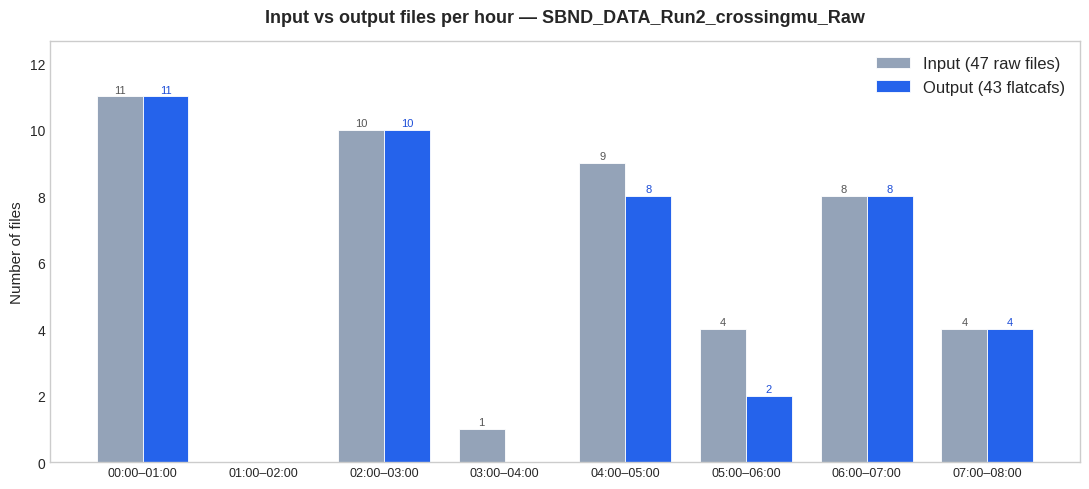

In [7]:
labels = [f"{d.strftime('%H:%M')}–{(d + timedelta(hours=1)).strftime('%H:%M')}" for d in dates]
inp = [fc if fc is not None else 0 for fc in file_counts]
out = output_counts

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(11, 5))

x = range(len(dates))
w = 0.38
bars_in  = ax.bar([i - w/2 for i in x], inp, width=w, label='Input (47 raw files)',
                   color='#94A3B8', edgecolor='white', linewidth=0.6)
bars_out = ax.bar([i + w/2 for i in x], out, width=w, label='Output (43 flatcafs)',
                   color='#2563EB', edgecolor='white', linewidth=0.6)

for bar in bars_in:
    h = bar.get_height()
    if h:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.05, str(int(h)),
                ha='center', va='bottom', fontsize=8, color='#555')
for bar in bars_out:
    h = bar.get_height()
    if h:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.05, str(int(h)),
                ha='center', va='bottom', fontsize=8, color='#1D4ED8')

ax.set_xticks(list(x))
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Number of files', fontsize=11)
ax.set_title(f'Input vs output files per hour — {input_dataset}',
             fontsize=13, fontweight='bold', pad=14)
ax.legend(fontsize=12)
ax.grid(visible=False)
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('auto_poms_bar_graph.png', dpi=150)
